In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

#### Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

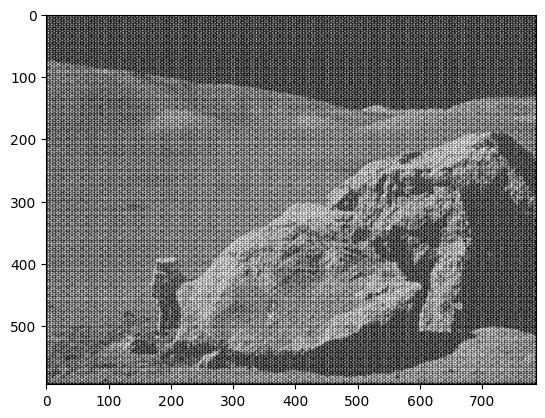

In [16]:
image = cv2.imread('periodic_noise.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')

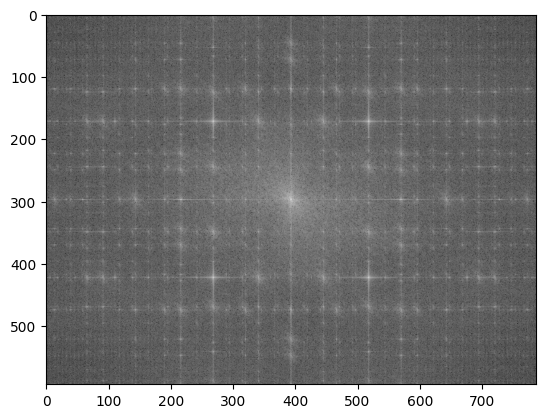

In [17]:
dft = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
magnitude_spectrum = 20 * np.log(1 + cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))

plt.imshow(magnitude_spectrum, cmap='gray')

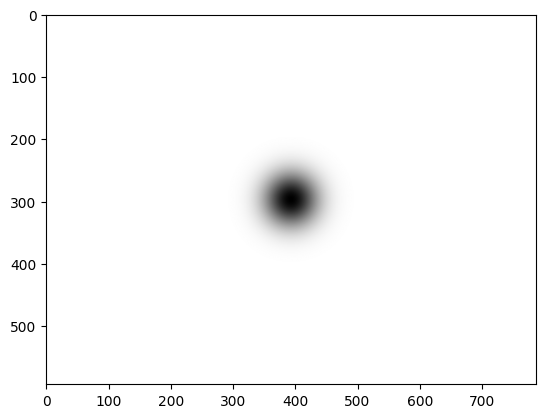

In [18]:
mask = np.zeros((image.shape[0], image.shape[1], 2), np.float32)
centerX, centerY = (int(image.shape[0] / 2), int(image.shape[1] / 2))
sigma = 30

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        D = (i - centerX) ** 2 + (j - centerY) ** 2
        mask[i, j, :] = 1 - np.exp(-D / (2 * sigma ** 2))

plt.imshow(mask[:, :, 0], cmap='gray')

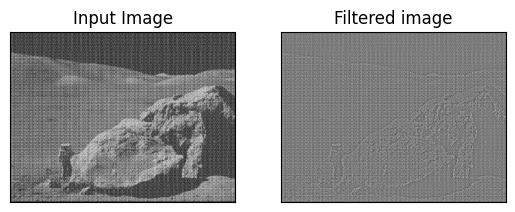

In [19]:
fshift = dft_shift * mask
f_ishift = np.fft.ifftshift(fshift, axes=(0,1))
image_back = cv2.idft(f_ishift, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)

plt.subplot(121), plt.imshow(image, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(image_back, cmap = 'gray')
plt.title('Filtered image'), plt.xticks([]), plt.yticks([])
plt.show()

#### Реализуйте вычисление свёртки (любой из изученных) с помощью преобразования Фурье

In [20]:
kernel = np.ones((5, 5), np.float32) / 25

In [21]:
image_pad = np.zeros((image.shape[0] + 4, image.shape[1] + 4), np.float32)
kernel_pad = np.zeros(image_pad.shape, np.float32)
image_pad[:image.shape[0], :image.shape[1]] = image
kernel_pad[:5, :5] = kernel

In [22]:
dft = cv2.dft(image_pad, flags=cv2.DFT_COMPLEX_OUTPUT)
dft_kernel = cv2.dft(kernel_pad, flags=cv2.DFT_COMPLEX_OUTPUT)

In [23]:
fshift = cv2.mulSpectrums(dft, dft_kernel, 0)
image_conv = cv2.idft(fshift, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)

image_conv = image_conv[2:2 + image.shape[0], 
                        2:2 + image.shape[1]]

Text(0.5, 1.0, 'convolution: averaging 5x5')

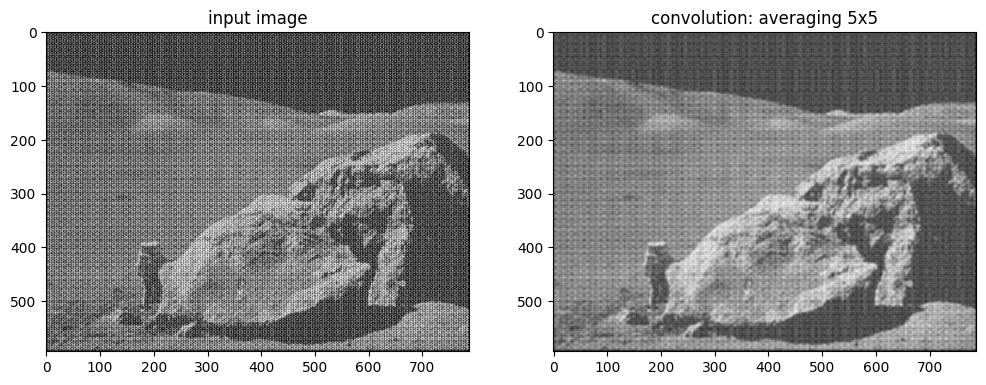

In [39]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('input image')
plt.subplot(1, 2, 2)
plt.imshow(image_conv, cmap='gray')
plt.title('convolution: averaging 5x5')

**Вывод**

изображение получилось сглаженным, сетка менее видна

#### Реализуйте удаление периодического шума с помощью преобразования Фурье

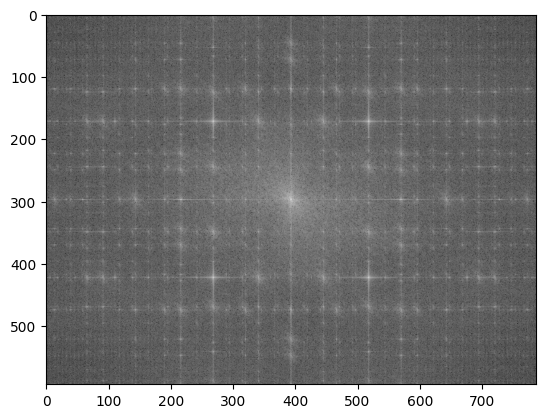

In [25]:
dft = cv2.dft(np.float32(image), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft, axes=(0, 1))
magnitude_spectrum = 20 * np.log(1 + cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))

plt.imshow(magnitude_spectrum, cmap='gray')

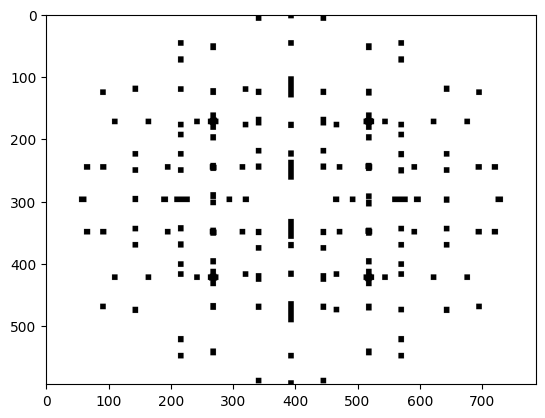

In [37]:
mask = np.ones(dft_shift.shape, np.float32)
centerX, centerY = (image.shape[0] // 2, image.shape[1] // 2)
r = 4
T = 250
r_center = 30
points_mask = magnitude_spectrum > T
points_mask[centerX - r_center:centerX + r_center + 1,
            centerY - r_center:centerY + r_center + 1] = False
points = np.argwhere(points_mask)

for x, y in points:
     mask[max(0, x - r):min(image.shape[0], x + r + 1),
         max(0, y - r):min(image.shape[1], y + r + 1), :] = 0

mask[centerX-r_center:centerX+r_center+1,
     centerY-r_center:centerY+r_center+1, :] = 1

plt.imshow(mask[:, :, 0], cmap='gray')

(np.float64(-0.5), np.float64(786.5), np.float64(593.5), np.float64(-0.5))

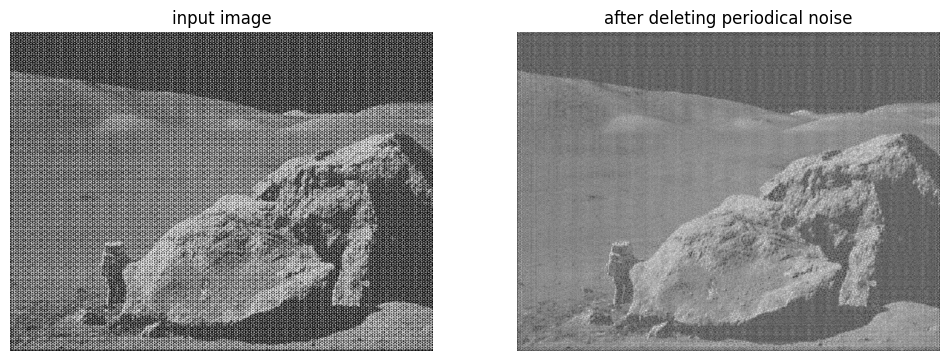

In [38]:
# применяем маску
fshift = dft_shift * mask

f_ishift = np.fft.ifftshift(fshift, axes=(0, 1))
image_back = cv2.idft(f_ishift, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)


plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('input image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_back, cmap='gray')
plt.title('after deleting periodical noise')
plt.axis('off')

**Вывод**

периодическая сетка стала гораздо менее заметной, но еще видна на темных участках